# HiLRP: Paper Visualizations & Extras

Every figure in *"One Trustable Explanation for Any Vision Transformer"* (TIP),
reproduced from cached result files, plus additional diagnostic visualizations.

**Runs end-to-end on cached data only** (the `results/` folder). No GPU, no model
downloads, no `lxt` needed: the attribution maps and metric CSVs were pre-computed.
Run *Cell 0* first, then any section independently.

| Part | Contents |
|---|---|
| **Setup** | imports, palette, helpers |
| **A. Paper figures** | assumption matrix, cross-architecture comparison, faithfulness-is-noise, qualitative gallery, stage-localized relevance, RQ2 pretraining, CLIP multi-modal |
| **B. Extra visualizations** | full benchmark heatmap, per-architecture bars, conservation-across-stages, signed vs. magnitude relevance, heavy-tail histogram, sparseness/pointing scatter, robustness, Shapley agreement, gamma sweep, HiLRP gallery |

Color follows the **Wong (2011) colorblind-safe** palette (already used in the paper:
`#0072B2 #E69F00 #D55E00 #009E73`); signed relevance uses a diverging red/blue map with
a neutral midpoint; magnitude uses a single-hue sequential ramp.

In [2]:
# --- Cell 0: setup (run first) ---------------------------------------------
import os, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl
warnings.filterwarnings("ignore")

# Locate the repo root (folder that contains results/ and figures/).
ROOT = Path.cwd()
for _ in range(4):
    if (ROOT / "results").is_dir() and (ROOT / "figures").is_dir():
        break
    ROOT = ROOT.parent
RES, FIG = ROOT / "results", ROOT / "figures"
assert RES.is_dir(), f"results/ not found from {Path.cwd()}"
print("repo root:", ROOT)

# Publication style (Times to match the paper).
mpl.rcParams.update({
    "font.family": "serif", "font.serif": ["Times New Roman", "DejaVu Serif"],
    "mathtext.fontset": "cm", "axes.titlesize": 12, "axes.labelsize": 11,
    "xtick.labelsize": 9, "ytick.labelsize": 9, "legend.fontsize": 9,
    "axes.spines.top": False, "axes.spines.right": False, "figure.dpi": 110,
})

# Wong colorblind-safe palette.
WONG = dict(blue="#0072B2", orange="#E69F00", vermillion="#D55E00",
            green="#009E73", sky="#56B4E9", yellow="#F0E442",
            purple="#CC79A7", black="#111111", grey="#8A8A8A")

MODEL_LABEL = {
    "resnet50": "ResNet-50", "convnext_base": "ConvNeXt-B",
    "vit_base_patch16_224": "ViT-B", "deit_base_patch16_224": "DeiT-B",
    "swin_base_patch4_window7_224": "Swin-B", "pvt_v2_b2": "PVT-v2",
    "mobilevitv2_100": "MobileViT", "efficientvit_b1": "EffViT-B1",
    "efficientvit_b2": "EffViT-B2", "maxvit_small_tf_224": "MaxViT",
}
METHOD_LABEL = {
    "grad_cam": "Grad-CAM", "grad_cam_plus_plus": "Grad-CAM++",
    "attention_rollout": "Att. Rollout", "attention_gradient": "Att.-grad",
    "saliency": "Saliency", "input_x_gradient": "Input$\\times$Grad",
    "integrated_gradients": "Integrated Grad", "smoothgrad": "SmoothGrad",
    "vargrad": "VarGrad", "gradient_shap": "GradientSHAP",
    "occlusion": "Occlusion", "rise": "RISE", "lime": "LIME", "hilrp": "HiLRP",
}
# Group each backbone into a family (for coloring / ordering).
FAMILY = {"resnet50": "CNN", "convnext_base": "CNN",
          "vit_base_patch16_224": "isotropic", "deit_base_patch16_224": "isotropic",
          "swin_base_patch4_window7_224": "hierarchical", "pvt_v2_b2": "hierarchical",
          "mobilevitv2_100": "hierarchical", "efficientvit_b1": "hierarchical",
          "efficientvit_b2": "hierarchical", "maxvit_small_tf_224": "hierarchical"}


def load_npy(subdir, key):
    p = RES / subdir / f"{key}.npy"
    return np.load(p) if p.exists() else None


def norm_signed(m, pct=99.0):
    """Percentile-clipped signed map + vmax for a diverging colormap."""
    m = np.asarray(m, float)
    v = np.percentile(np.abs(m), pct) + 1e-12
    return np.clip(m, -v, v), v


def heat_overlay(ax, rgb, mp, sigma=2.0, cmap="turbo"):
    """Smoothed |relevance| overlay on the desaturated input (paper style)."""
    from scipy.ndimage import gaussian_filter, zoom
    h = np.abs(np.asarray(mp, float))
    if h.shape[0] != rgb.shape[0]:
        h = zoom(h, rgb.shape[0] / h.shape[0], order=1)
    h = gaussian_filter(h, sigma)
    h = np.clip(h / (np.percentile(h, 99.0) + 1e-12), 0, 1)
    gray = rgb.mean(2, keepdims=True).repeat(3, 2) * 0.55 + 0.15
    ax.imshow(gray)
    ax.imshow(h, cmap=cmap, alpha=np.clip(h * 1.1, 0, 1))
    ax.axis("off")

print("setup complete - helpers: load_npy, norm_signed, heat_overlay")

repo root: c:\Users\nisha\OneDrive\Desktop\Research\Explainable Bench Mark
setup complete - helpers: load_npy, norm_signed, heat_overlay


---
## Part A. Paper figures
Each cell reproduces one figure from the paper (or displays the saved asset when the
underlying per-pixel data is not cached as arrays).

### A1 &middot; Figure 1 — Assumption matrix
Which attribution family survives which backbone. A green check = the family's
architectural assumption holds; amber half = runs but degraded; red cross = undefined
or fails. Only HiLRP (bottom row) is solid across the grid.

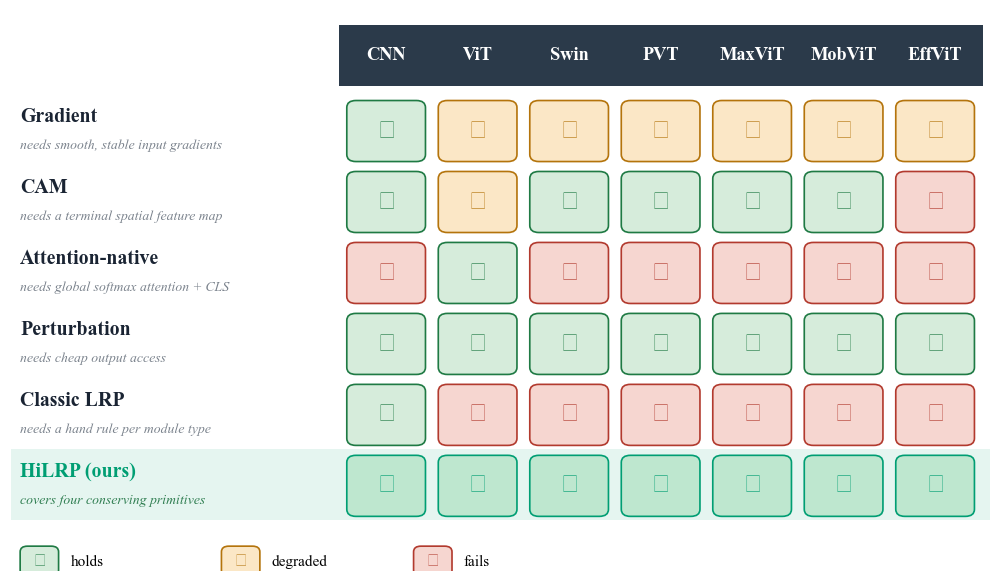

In [3]:
from matplotlib.patches import FancyBboxPatch, Rectangle
C_OURS = WONG["green"]
FACE = {"H": "#D6ECDB", "D": "#FBE7C6", "F": "#F6D6D0"}
EDGE = {"H": "#1F7A44", "D": "#B4740C", "F": "#B23A2E"}
GLYPH = {"H": "✓", "D": "◐", "F": "✗"}
cols = ["CNN", "ViT", "Swin", "PVT", "MaxViT", "MobViT", "EffViT"]
rows = [("Gradient", "smooth, stable input gradients", "HDDDDDD"),
        ("CAM", "a terminal spatial feature map", "HDHHHHF"),
        ("Attention-native", "global softmax attention + CLS", "FHFFFFF"),
        ("Perturbation", "cheap output access", "HHHHHHH"),
        ("Classic LRP", "a hand rule per module type", "HFFFFFF"),
        ("HiLRP (ours)", "four conserving primitives", "HHHHHHH")]
nr, nc = len(rows), len(cols)
fig, ax = plt.subplots(figsize=(9.2, 5.4))
ax.set_xlim(-3.6, nc + 0.1); ax.set_ylim(nr + 0.7, -1.2); ax.axis("off")
ax.add_patch(Rectangle((-0.02, -1.0), nc + 0.04, 0.86, facecolor="#2B3A4A", ec="none"))
for j, c in enumerate(cols):
    ax.text(j + 0.5, -0.57, c, ha="center", va="center", fontsize=12,
            fontweight="bold", color="white")
for i, (fam, assume, st) in enumerate(rows):
    ours = fam.startswith("HiLRP")
    if ours:
        ax.add_patch(Rectangle((-3.6, i - 0.02), nc + 3.7, 1.0, facecolor=C_OURS,
                               alpha=0.10, ec="none", zorder=0))
    ax.text(-3.5, i + 0.3, fam, ha="left", va="center", fontsize=13,
            fontweight="bold", color=C_OURS if ours else "#1A2433")
    ax.text(-3.5, i + 0.7, ("covers " if ours else "needs ") + assume, ha="left",
            va="center", fontsize=9, style="italic",
            color="#2E7D50" if ours else "#7A828C")
    for j, s in enumerate(st):
        face = "#BEE7CF" if ours else FACE[s]
        edge = C_OURS if ours else EDGE[s]
        ax.add_patch(FancyBboxPatch((j + 0.07, i + 0.07), 0.86, 0.86,
                     boxstyle="round,pad=0,rounding_size=0.1", fc=face, ec=edge, lw=1.1))
        ax.text(j + 0.5, i + 0.5, GLYPH[s], ha="center", va="center", fontsize=17,
                fontweight="bold", color=edge)
for lx, s, t in [(-3.5, "H", "holds"), (-1.3, "D", "degraded"), (0.8, "F", "fails")]:
    ax.add_patch(FancyBboxPatch((lx, nr + 0.35, ), 0.42, 0.42,
                 boxstyle="round,pad=0,rounding_size=0.08", fc=FACE[s], ec=EDGE[s], lw=1.1))
    ax.text(lx + 0.21, nr + 0.56, GLYPH[s], ha="center", va="center",
            fontsize=12, color=EDGE[s], fontweight="bold")
    ax.text(lx + 0.55, nr + 0.56, t, ha="left", va="center", fontsize=10)
plt.tight_layout(); plt.show()

### A2 &middot; Figure 3 — The same image, the same methods, four backbones
Only the backbone changes down the rows, so every difference is caused by the
architecture. On **EfficientViT-B2** Grad-CAM collapses (its linear attention removes
the spatial feature map CAM needs) while HiLRP still localizes the cheetah's face.

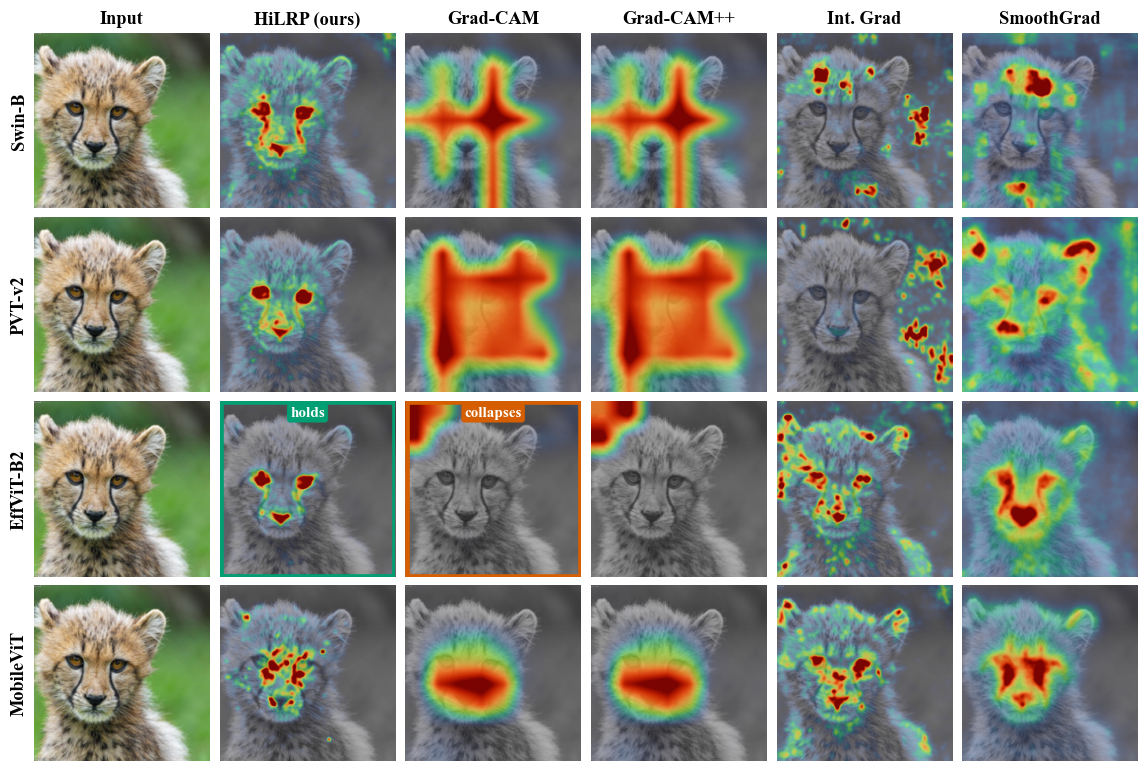

In [4]:
TMP = "cheetah_tmp"
rgb = load_npy(TMP, "__input")
models = ["swin_base_patch4_window7_224", "pvt_v2_b2", "efficientvit_b2", "mobilevitv2_100"]
methods = ["hilrp", "grad_cam", "grad_cam_plus_plus", "integrated_gradients", "smoothgrad"]
titles = ["Input", "HiLRP (ours)", "Grad-CAM", "Grad-CAM++", "Int. Grad", "SmoothGrad"]
if rgb is None:
    print("cheetah_tmp not found - run scripts/bench/cheetah_comparison.py first")
else:
    fig, ax = plt.subplots(len(models), len(methods) + 1, figsize=(13, 8.6))
    for r, m in enumerate(models):
        ax[r, 0].imshow(rgb); ax[r, 0].set_xticks([]); ax[r, 0].set_yticks([])
        ax[r, 0].set_ylabel(MODEL_LABEL[m], fontsize=12, fontweight="bold")
        for s in ax[r, 0].spines.values(): s.set_visible(False)
        for c, meth in enumerate(methods, 1):
            mp = load_npy(TMP, f"{m}__{meth}")
            if mp is not None: heat_overlay(ax[r, c], rgb, mp)
            else: ax[r, c].axis("off")
    for c, t in enumerate(titles): ax[0, c].set_title(t, fontsize=12, fontweight="bold")
    # flag the EfficientViT collapse
    for (r, c, col, txt) in [(2, 1, WONG["green"], "holds"), (2, 2, WONG["vermillion"], "collapses")]:
        ax[r, c].add_patch(Rectangle((1, 1), 221, 221, fill=False, ec=col, lw=3))
        ax[r, c].text(0.5, 0.97, txt, transform=ax[r, c].transAxes, ha="center", va="top",
                      fontsize=10, color="white", fontweight="bold",
                      bbox=dict(boxstyle="round,pad=0.2", fc=col, ec="none"))
    plt.subplots_adjust(wspace=0.03, hspace=0.05); plt.show()

### A3 &middot; Figure 4 — Faithfulness Correlation cannot referee modern ViTs
Every model-method cell's Faithfulness Correlation clusters at zero, well inside the
per-image noise. A metric that scores good and bad localizers the same cannot arbitrate.

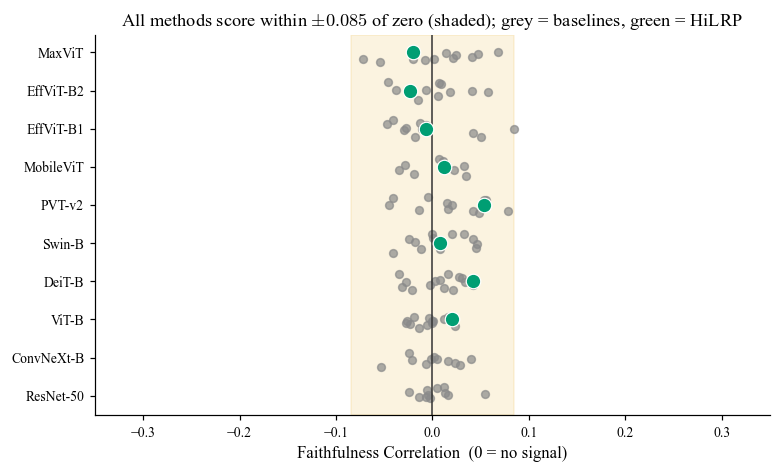

global FC:  mean +0.0044   max|.| 0.085


In [5]:
df = pd.read_csv(RES / "clean_summary.csv")
fc = df.dropna(subset=["faithfulness_corr"]).copy()
fig, ax = plt.subplots(figsize=(7.2, 4.4))
order = [m for m in MODEL_LABEL if m in set(fc["model"])]
for i, m in enumerate(order):
    vals = fc.loc[fc.model == m, "faithfulness_corr"].values
    jit = (np.random.RandomState(i).rand(len(vals)) - 0.5) * 0.5
    hil = fc.loc[(fc.model == m) & (fc.method == "hilrp"), "faithfulness_corr"].values
    ax.scatter(vals, i + jit, s=26, color=WONG["grey"], alpha=0.7, zorder=2)
    if len(hil): ax.scatter(hil, [i], s=90, color=WONG["green"], zorder=3,
                            edgecolor="white", linewidth=0.8, label="HiLRP" if i == 0 else None)
ax.axvline(0, color="#333", lw=1)
ax.axvspan(-0.085, 0.085, color=WONG["orange"], alpha=0.12, zorder=0)
ax.set_yticks(range(len(order))); ax.set_yticklabels([MODEL_LABEL[m] for m in order])
ax.set_xlabel("Faithfulness Correlation  (0 = no signal)"); ax.set_xlim(-0.35, 0.35)
ax.set_title("All methods score within $\\pm0.085$ of zero (shaded); grey = baselines, green = HiLRP")
ax.legend(loc="lower right", frameon=False); plt.tight_layout(); plt.show()
print("global FC:  mean %+.4f   max|.| %.3f" % (fc.faithfulness_corr.mean(), fc.faithfulness_corr.abs().max()))

### A4 &middot; Figure 5 — Qualitative gallery on PVT-v2
HiLRP traces object structure (eyes, muzzle, markings); Grad-CAM / Grad-CAM++ make
low-resolution blobs, often hollow over the object; Integrated Gradients scatters.

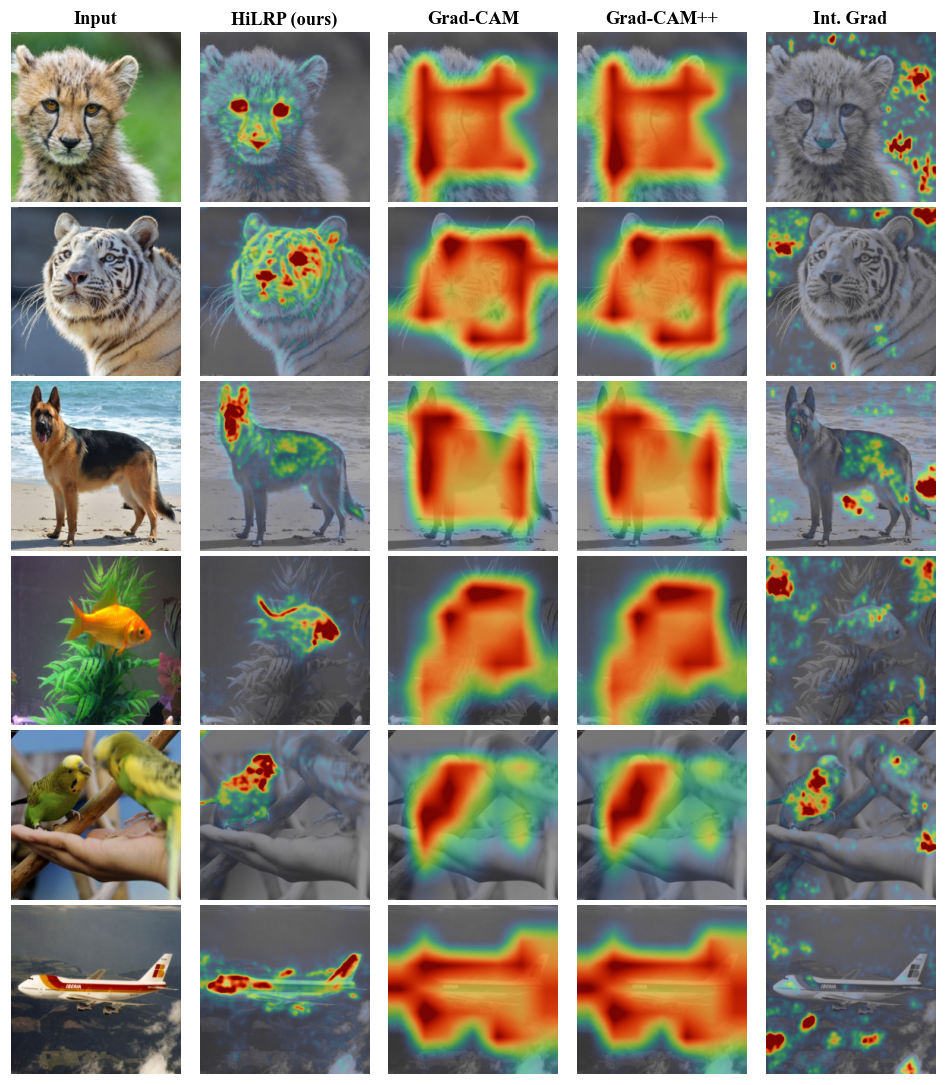

In [6]:
GAL = "qual_gallery"
picks = ["cheetah", "tiger", "german-shepherd", "goldfish", "parrot", "plane"]
picks = [p for p in picks if (RES / GAL / f"{p}__hilrp.npy").exists()][:6]
mcols = ["hilrp", "grad_cam", "grad_cam_plus_plus", "integrated_gradients"]
tcols = ["Input", "HiLRP (ours)", "Grad-CAM", "Grad-CAM++", "Int. Grad"]
fig, ax = plt.subplots(len(picks), len(mcols) + 1, figsize=(11, 2.05 * len(picks)))
for r, name in enumerate(picks):
    rgb = load_npy(GAL, f"{name}__input")
    ax[r, 0].imshow(rgb); ax[r, 0].axis("off")
    for c, meth in enumerate(mcols, 1):
        mp = load_npy(GAL, f"{name}__{meth}")
        if mp is not None: heat_overlay(ax[r, c], rgb, mp)
        else: ax[r, c].axis("off")
for c, t in enumerate(tcols): ax[0, c].set_title(t, fontsize=12, fontweight="bold")
plt.subplots_adjust(wspace=0.03, hspace=0.03); plt.show()

### A5 &middot; Figure 6 — Stage-localized relevance
Because relevance is conserved at every layer, HiLRP reads out a valid map at each
resolution stage. The saved figure (top) shows the progression fine&rarr;semantic;
below, the measured conservation ratio at each stage (1.0 = exact) from
`conservation.csv`, quantifying where the pixel-level $\gamma$-rule deviates.

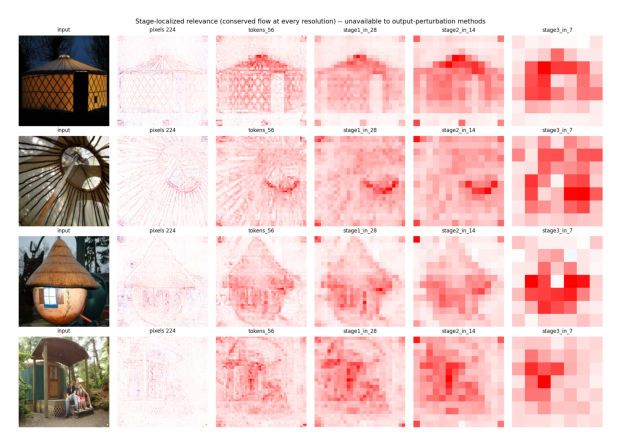

In [7]:
import matplotlib.image as mpimg
p = FIG / "hilrp" / "stage_localization.png"
if p.exists():
    fig, ax = plt.subplots(figsize=(12, 5)); ax.imshow(mpimg.imread(p)); ax.axis("off"); plt.show()
else:
    print("stage_localization.png not found")

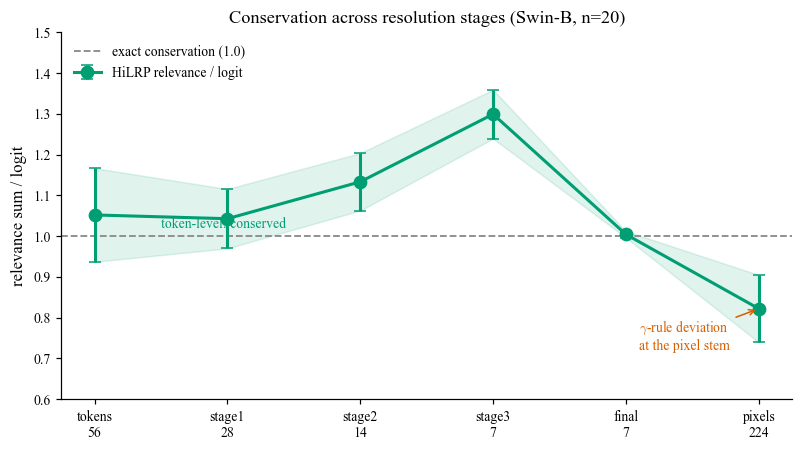

In [8]:
cons = pd.read_csv(RES / "hilrp_gate2real" / "conservation.csv")
stages = ["tokens_56", "stage1_in_28", "stage2_in_14", "stage3_in_7", "final_7", "pixels"]
labels = ["tokens\n56", "stage1\n28", "stage2\n14", "stage3\n7", "final\n7", "pixels\n224"]
mean, std = cons[stages].mean(), cons[stages].std()
fig, ax = plt.subplots(figsize=(7.4, 4.2))
x = range(len(stages))
ax.axhline(1.0, color=WONG["grey"], ls="--", lw=1.2, label="exact conservation (1.0)")
ax.errorbar(x, mean.values, yerr=std.values, marker="o", ms=8, lw=2, color=WONG["green"],
            capsize=4, label="HiLRP relevance / logit")
ax.fill_between(x, mean.values - std.values, mean.values + std.values, color=WONG["green"], alpha=0.12)
ax.set_xticks(list(x)); ax.set_xticklabels(labels)
ax.set_ylabel("relevance sum / logit"); ax.set_ylim(0.6, 1.5)
ax.set_title("Conservation across resolution stages (Swin-B, n=%d)" % len(cons))
ax.annotate("token-level: conserved", (0.5, 1.02), fontsize=9, color=WONG["green"])
ax.annotate("$\\gamma$-rule deviation\nat the pixel stem", (5, mean.values[-1]),
            xytext=(4.1, 0.72), fontsize=9, color=WONG["vermillion"],
            arrowprops=dict(arrowstyle="->", color=WONG["vermillion"]))
ax.legend(frameon=False, loc="upper left"); plt.tight_layout(); plt.show()

### A6 &middot; Figure 7 — Pretraining objective shapes the explanation
One fixed ViT-B/16, four pretrainings, one common label-free scalar (view-invariance).
The maps disagree (mean pairwise Spearman 0.33), so the *objective*, not the
architecture, drives the explanation. DINO localizes best with no labels; MAE routes
almost no relevance to pixels.

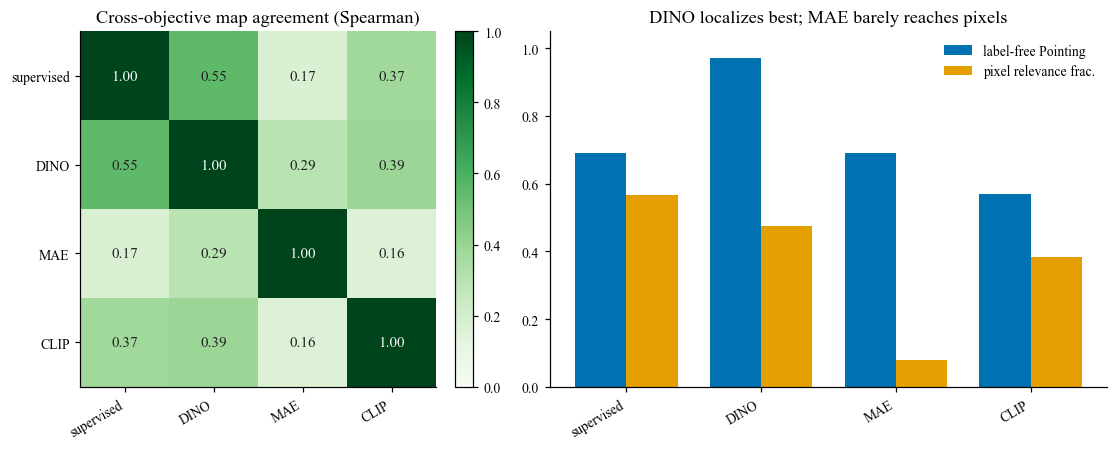

In [9]:
rq = pd.read_csv(RES / "rq2_pretraining" / "summary.csv")
S = load_npy("rq2_pretraining", "cross_objective_spearman")
objs = list(rq["objective"])
fig, ax = plt.subplots(1, 2, figsize=(11, 4.2), gridspec_kw=dict(width_ratios=[1, 1.15]))
# left: agreement matrix (sequential, single hue)
im = ax[0].imshow(S, cmap="Greens", vmin=0, vmax=1)
ax[0].set_xticks(range(len(objs))); ax[0].set_xticklabels(objs, rotation=30, ha="right")
ax[0].set_yticks(range(len(objs))); ax[0].set_yticklabels(objs)
for i in range(len(objs)):
    for j in range(len(objs)):
        ax[0].text(j, i, f"{S[i,j]:.2f}", ha="center", va="center",
                   color="white" if S[i, j] > 0.6 else "#222", fontsize=10)
ax[0].set_title("Cross-objective map agreement (Spearman)")
fig.colorbar(im, ax=ax[0], fraction=0.046, pad=0.04)
# right: label-free pointing & pixel relevance
xpos = np.arange(len(objs)); w = 0.38
ax[1].bar(xpos - w/2, rq["labelfree_pointing"], w, color=WONG["blue"], label="label-free Pointing")
ax[1].bar(xpos + w/2, rq["pixel_cons"], w, color=WONG["orange"], label="pixel relevance frac.")
ax[1].set_xticks(xpos); ax[1].set_xticklabels(objs, rotation=30, ha="right")
ax[1].set_ylim(0, 1.05); ax[1].set_title("DINO localizes best; MAE barely reaches pixels")
ax[1].legend(frameon=False); plt.tight_layout(); plt.show()

### A7 &middot; Figure 8 — Cross-modal attribution on CLIP
HiLRP attributes the image-text similarity with the caption embedding frozen. The map
is text-conditioned: a matching caption ("a photo of a yurt") differs from a mismatched
one ("a photo of a dog"), with no new rule.

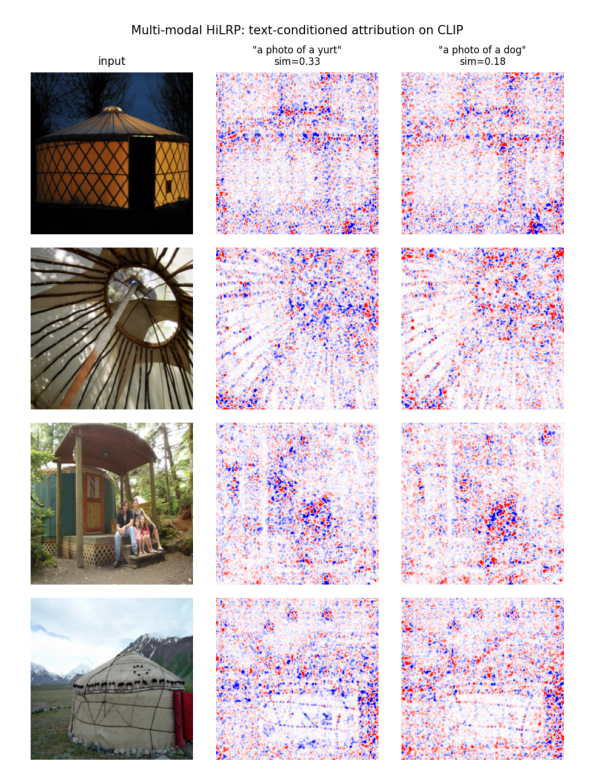

In [10]:
p = FIG / "hilrp" / "clip_multimodal.png"
if p.exists():
    fig, ax = plt.subplots(figsize=(7.5, 9)); ax.imshow(mpimg.imread(p)); ax.axis("off"); plt.show()
else:
    print("clip_multimodal.png not found")

---
## Part B. Additional visualizations
New views built from the same cached metric CSVs and attribution arrays.

### B1 &middot; The whole benchmark at a glance
Pointing Game for all 10 backbones &times; 14 methods (the visual form of Table II).
Sequential single-hue ramp (higher = better). Note Grad-CAM's bright row dropping to
0.55 on EfficientViT-B2, and HiLRP's consistently strong row.

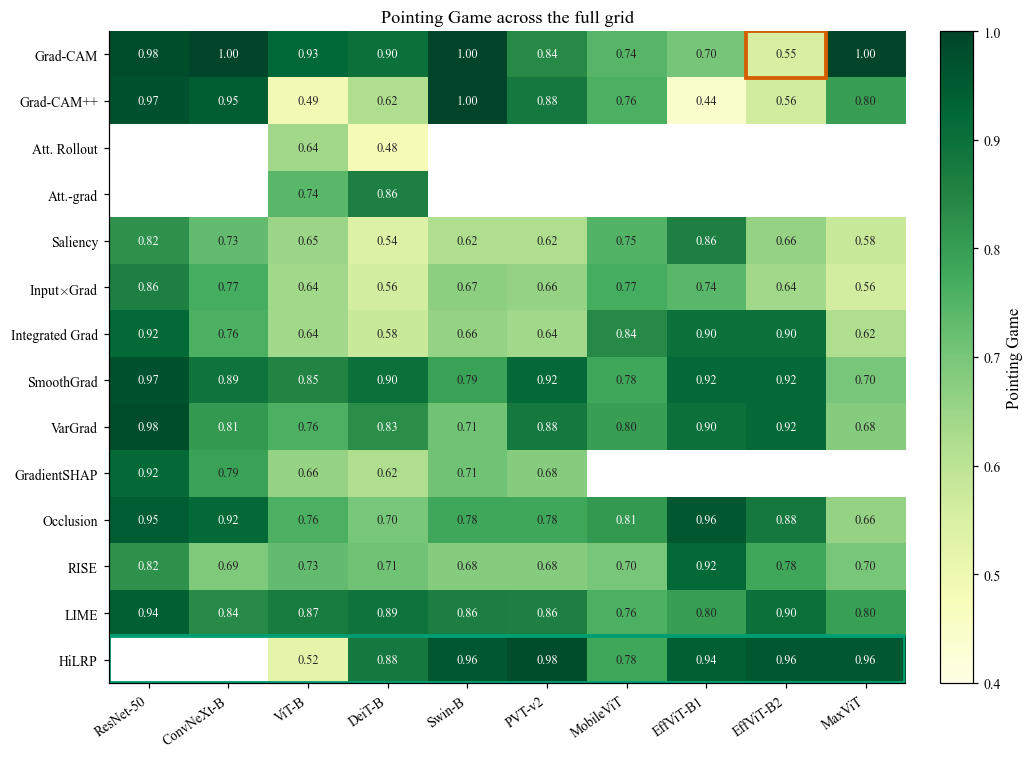

In [11]:
df = pd.read_csv(RES / "clean_summary.csv")
piv = df.pivot_table(index="method", columns="model", values="pointing_game")
mord = [m for m in MODEL_LABEL if m in piv.columns]
meth_ord = ["grad_cam", "grad_cam_plus_plus", "attention_rollout", "attention_gradient",
            "saliency", "input_x_gradient", "integrated_gradients", "smoothgrad", "vargrad",
            "gradient_shap", "occlusion", "rise", "lime", "hilrp"]
meth_ord = [m for m in meth_ord if m in piv.index]
M = piv.loc[meth_ord, mord]
fig, ax = plt.subplots(figsize=(9.5, 7))
im = ax.imshow(M.values, cmap="YlGn", vmin=0.4, vmax=1.0, aspect="auto")
ax.set_xticks(range(len(mord))); ax.set_xticklabels([MODEL_LABEL[m] for m in mord], rotation=35, ha="right")
ax.set_yticks(range(len(meth_ord))); ax.set_yticklabels([METHOD_LABEL[m] for m in meth_ord])
for i in range(M.shape[0]):
    for j in range(M.shape[1]):
        v = M.values[i, j]
        if not np.isnan(v):
            ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=8,
                    color="white" if v > 0.8 else "#222")
# highlight HiLRP row and the EffViT-B2 Grad-CAM collapse
hr = meth_ord.index("hilrp")
ax.add_patch(Rectangle((-0.5, hr - 0.5), len(mord), 1, fill=False, ec=WONG["green"], lw=2.5))
if "efficientvit_b2" in mord and "grad_cam" in meth_ord:
    ax.add_patch(Rectangle((mord.index("efficientvit_b2") - 0.5, meth_ord.index("grad_cam") - 0.5),
                           1, 1, fill=False, ec=WONG["vermillion"], lw=2.5))
fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04, label="Pointing Game")
ax.set_title("Pointing Game across the full grid"); plt.tight_layout(); plt.show()

### B2 &middot; Where CAM breaks and HiLRP holds
Per-architecture Pointing for four representative methods. Grad-CAM swings wildly
(1.0 &rarr; 0.55); HiLRP stays high across families.

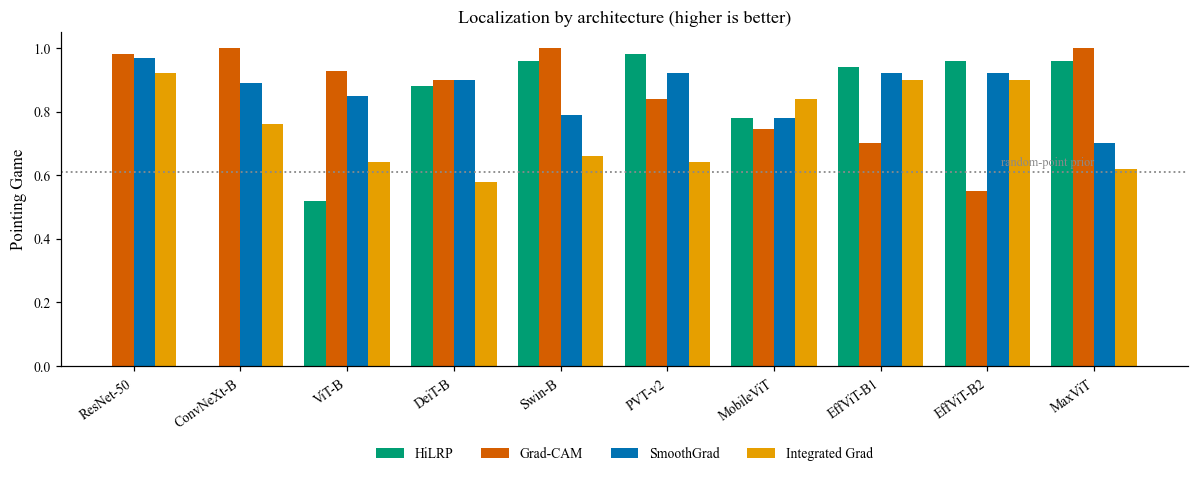

In [11]:
df = pd.read_csv(RES / "clean_summary.csv")
sel = ["hilrp", "grad_cam", "smoothgrad", "integrated_gradients"]
cmap = {"hilrp": WONG["green"], "grad_cam": WONG["vermillion"],
        "smoothgrad": WONG["blue"], "integrated_gradients": WONG["orange"]}
mord = [m for m in MODEL_LABEL if m in set(df.model)]
x = np.arange(len(mord)); w = 0.2
fig, ax = plt.subplots(figsize=(11, 4.6))
for k, meth in enumerate(sel):
    vals = [df.loc[(df.model == m) & (df.method == meth), "pointing_game"].mean() for m in mord]
    ax.bar(x + (k - 1.5) * w, vals, w, color=cmap[meth], label=METHOD_LABEL[meth])
ax.axhline(0.61, color=WONG["grey"], ls=":", lw=1.2)
ax.text(len(mord) - 1, 0.63, "random-point prior", fontsize=8, color=WONG["grey"], ha="right")
ax.set_xticks(x); ax.set_xticklabels([MODEL_LABEL[m] for m in mord], rotation=35, ha="right")
ax.set_ylabel("Pointing Game"); ax.set_ylim(0, 1.05)
ax.set_title("Localization by architecture (higher is better)")
ax.legend(ncol=4, frameon=False, loc="lower center", bbox_to_anchor=(0.5, -0.32))
plt.tight_layout(); plt.show()

### B3 &middot; Signed relevance vs. magnitude
HiLRP relevance is **signed**: red = evidence *for* the class, blue = evidence *against*.
The magnitude overlay (right of each pair) is what localization metrics see, but the
signed map (diverging red/blue, neutral midpoint) carries the completeness semantics.

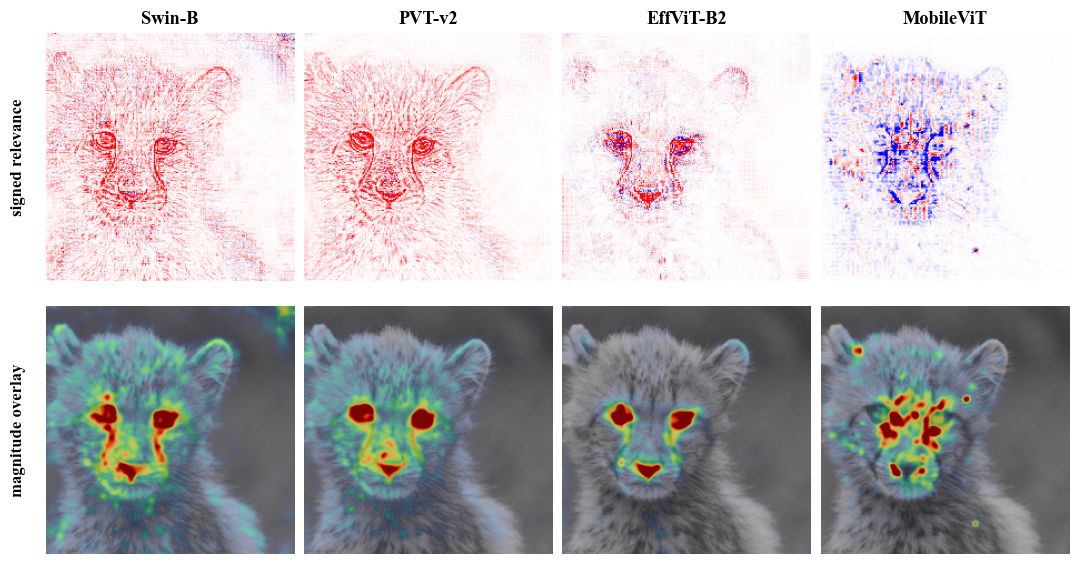

In [12]:
TMP = "cheetah_tmp"
rgb = load_npy(TMP, "__input")
models = ["swin_base_patch4_window7_224", "pvt_v2_b2", "efficientvit_b2", "mobilevitv2_100"]
fig, ax = plt.subplots(2, len(models), figsize=(12, 6.2))
for c, m in enumerate(models):
    mp = load_npy(TMP, f"{m}__hilrp")
    disp, v = norm_signed(mp, 99.0)
    ax[0, c].imshow(disp, cmap="bwr", vmin=-v, vmax=v); ax[0, c].axis("off")
    ax[0, c].set_title(MODEL_LABEL[m], fontsize=12, fontweight="bold")
    heat_overlay(ax[1, c], rgb, mp)
ax[0, 0].set_ylabel("signed (bwr)"); ax[1, 0].set_ylabel("magnitude")
for r, lab in enumerate(["signed relevance", "magnitude overlay"]):
    ax[r, 0].text(-0.08, 0.5, lab, transform=ax[r, 0].transAxes, rotation=90,
                  va="center", ha="right", fontsize=11, fontweight="bold")
plt.subplots_adjust(wspace=0.04, hspace=0.08); plt.show()

### B4 &middot; Why we clip at the 99th percentile
HiLRP relevance is heavy-tailed: a few pixels hold most of the mass. Plotting the raw
map saturates to a blank; the paper renders at the 99th-percentile clip. Here is the
distribution of $|$relevance$|$ that motivates it.

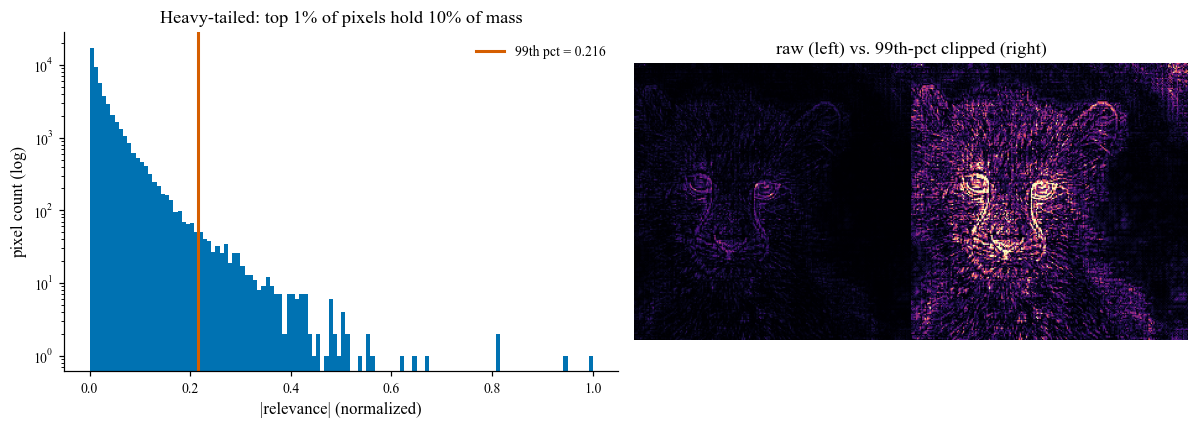

In [13]:
mp = load_npy("cheetah_tmp", "swin_base_patch4_window7_224__hilrp")
a = np.abs(mp.ravel()); a = a / a.max()
p99 = np.percentile(a, 99)
top1_mass = a[a >= p99].sum() / a.sum()
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].hist(a, bins=120, color=WONG["blue"]); ax[0].set_yscale("log")
ax[0].axvline(p99, color=WONG["vermillion"], lw=2, label=f"99th pct = {p99:.3f}")
ax[0].set_xlabel("|relevance| (normalized)"); ax[0].set_ylabel("pixel count (log)")
ax[0].set_title(f"Heavy-tailed: top 1% of pixels hold {top1_mass*100:.0f}% of mass")
ax[0].legend(frameon=False)
# effect of the clip on the displayed map
d_raw = np.clip(np.abs(mp), 0, np.abs(mp).max())
d_clip = np.clip(np.abs(mp), 0, np.percentile(np.abs(mp), 99))
ax[1].imshow(np.concatenate([d_raw / d_raw.max(), d_clip / d_clip.max()], axis=1), cmap="magma")
ax[1].axis("off"); ax[1].set_title("raw (left) vs. 99th-pct clipped (right)")
plt.tight_layout(); plt.show()

### B5 &middot; Sparseness vs. localization
Each point is one model-method cell, colored by backbone family. HiLRP (ringed) sits in
the sparse, well-localizing region; perturbation/attention methods are diffuse.

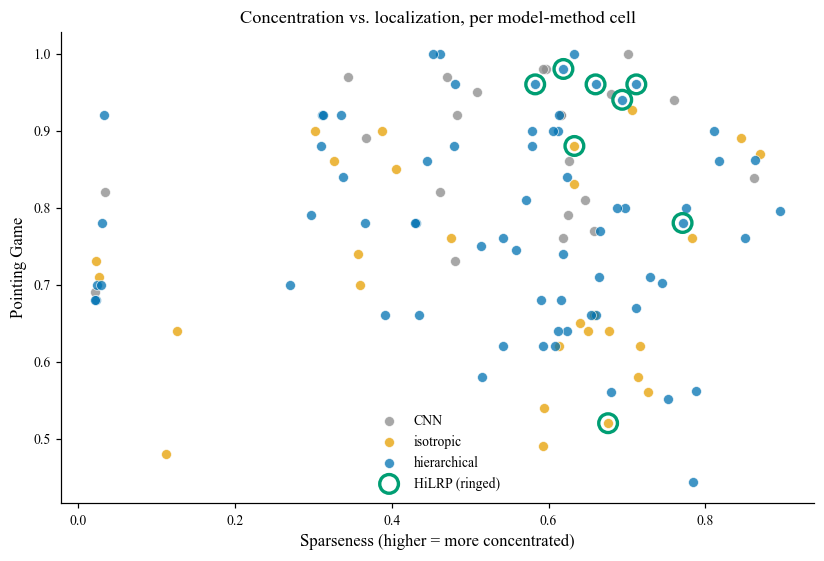

In [14]:
df = pd.read_csv(RES / "clean_summary.csv").dropna(subset=["sparseness", "pointing_game"])
fam_col = {"CNN": WONG["grey"], "isotropic": WONG["orange"], "hierarchical": WONG["blue"]}
fig, ax = plt.subplots(figsize=(7.6, 5.2))
for fam, col in fam_col.items():
    sub = df[df.model.map(FAMILY) == fam]
    ax.scatter(sub.sparseness, sub.pointing_game, s=42, color=col, alpha=0.75,
               edgecolor="white", linewidth=0.5, label=fam)
hil = df[df.method == "hilrp"]
ax.scatter(hil.sparseness, hil.pointing_game, s=150, facecolor="none",
           edgecolor=WONG["green"], linewidth=2.2, label="HiLRP (ringed)", zorder=5)
ax.set_xlabel("Sparseness (higher = more concentrated)")
ax.set_ylabel("Pointing Game"); ax.set_title("Concentration vs. localization, per model-method cell")
ax.legend(frameon=False); plt.tight_layout(); plt.show()

### B6 &middot; Robustness (Max-Sensitivity) of HiLRP
Lower is more stable. HiLRP is stable on Swin/PVT/EfficientViT and spikes only on the
convolution-heavy MobileViT stem, an honest limitation reported in the paper.

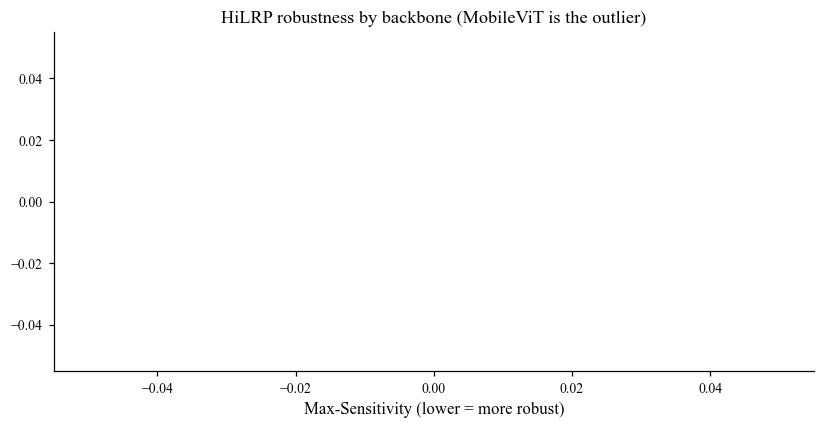

In [15]:
try:
    allr = pd.read_csv(RES / "all_results_sofar.csv")
    hil = allr[allr.method == "hilrp"].dropna(subset=["max_sensitivity_mean"])
    hil = hil[hil.model.isin(MODEL_LABEL)].drop_duplicates("model")
    hil["lab"] = hil.model.map(MODEL_LABEL)
    hil = hil.sort_values("max_sensitivity_mean")
    fig, ax = plt.subplots(figsize=(7.6, 4))
    cols = [WONG["vermillion"] if v > 3 else WONG["green"] for v in hil.max_sensitivity_mean]
    ax.barh(hil.lab, hil.max_sensitivity_mean, color=cols,
            xerr=hil.get("max_sensitivity_std"), capsize=3)
    ax.set_xlabel("Max-Sensitivity (lower = more robust)")
    ax.set_title("HiLRP robustness by backbone (MobileViT is the outlier)")
    plt.tight_layout(); plt.show()
except Exception as e:
    print("max_sensitivity not available:", e)

### B7 &middot; Agreement with axiomatic Shapley values
An independent yardstick (Spearman agreement with sampled segment-Shapley). HiLRP leads
on all three; Grad-CAM collapses on EfficientViT exactly where its Pointing does.

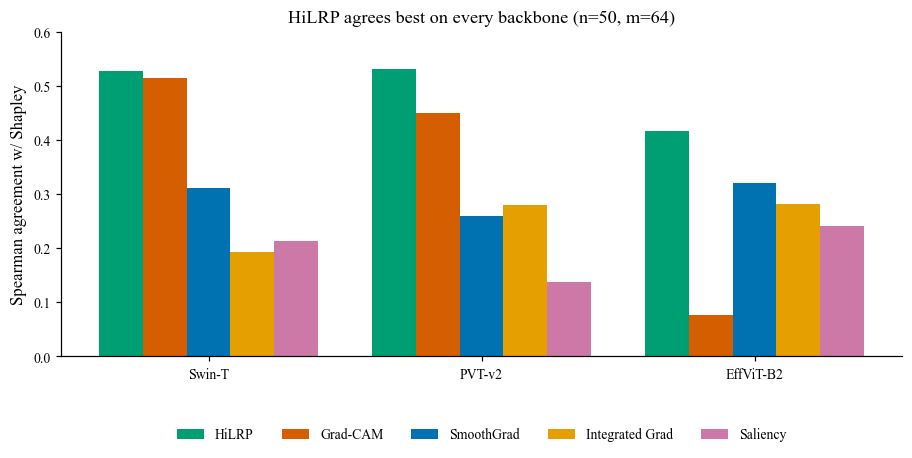

In [16]:
shap = pd.DataFrame({
    "method": ["HiLRP", "Grad-CAM", "SmoothGrad", "Integrated Grad", "Saliency"],
    "Swin-T": [0.528, 0.515, 0.312, 0.192, 0.214],
    "PVT-v2": [0.531, 0.449, 0.260, 0.279, 0.137],
    "EffViT-B2": [0.417, 0.077, 0.321, 0.281, 0.240]})
back = ["Swin-T", "PVT-v2", "EffViT-B2"]
x = np.arange(len(back)); w = 0.16
colors = [WONG["green"], WONG["vermillion"], WONG["blue"], WONG["orange"], WONG["purple"]]
fig, ax = plt.subplots(figsize=(8.4, 4.4))
for k, (_, row) in enumerate(shap.iterrows()):
    ax.bar(x + (k - 2) * w, [row[b] for b in back], w, color=colors[k], label=row["method"])
ax.set_xticks(x); ax.set_xticklabels(back); ax.set_ylabel("Spearman agreement w/ Shapley")
ax.set_ylim(0, 0.6); ax.set_title("HiLRP agrees best on every backbone (n=50, m=64)")
ax.legend(ncol=5, frameon=False, loc="lower center", bbox_to_anchor=(0.5, -0.3))
plt.tight_layout(); plt.show()

### B8 &middot; The single free hyperparameter: $\gamma$
Localization vs. $\gamma$ on three backbones. $\gamma{=}0.25$ (dashed) sits at or within
one image of the best Pointing on every backbone, so it is fixed for all experiments.

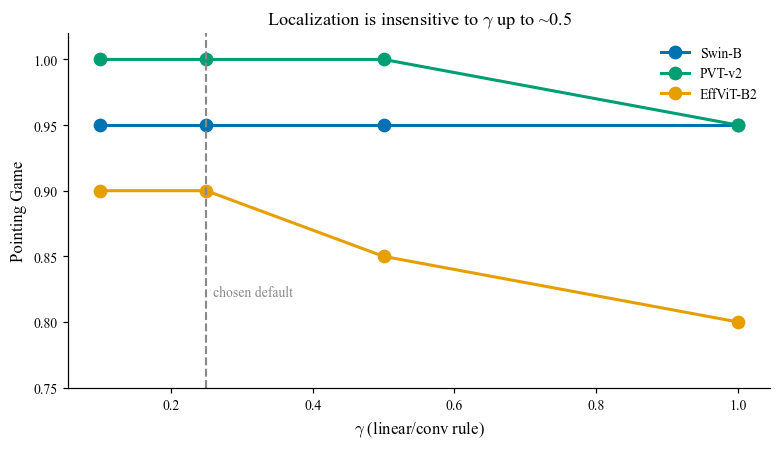

In [17]:
g = [0.1, 0.25, 0.5, 1.0]
data = {"Swin-B": [0.95, 0.95, 0.95, 0.95], "PVT-v2": [1.00, 1.00, 1.00, 0.95],
        "EffViT-B2": [0.90, 0.90, 0.85, 0.80]}
cmap = {"Swin-B": WONG["blue"], "PVT-v2": WONG["green"], "EffViT-B2": WONG["orange"]}
fig, ax = plt.subplots(figsize=(7.2, 4.2))
for k, v in data.items():
    ax.plot(g, v, marker="o", ms=8, lw=2, color=cmap[k], label=k)
ax.axvline(0.25, color=WONG["grey"], ls="--", lw=1.4)
ax.text(0.26, 0.82, "chosen default", fontsize=9, color=WONG["grey"])
ax.set_xlabel("$\\gamma$ (linear/conv rule)"); ax.set_ylabel("Pointing Game")
ax.set_ylim(0.75, 1.02); ax.set_title("Localization is insensitive to $\\gamma$ up to ~0.5")
ax.legend(frameon=False); plt.tight_layout(); plt.show()

### B9 &middot; HiLRP gallery across many classes
HiLRP magnitude overlays (PVT-v2) for every cached image, showing consistent
object-structure localization across diverse categories.

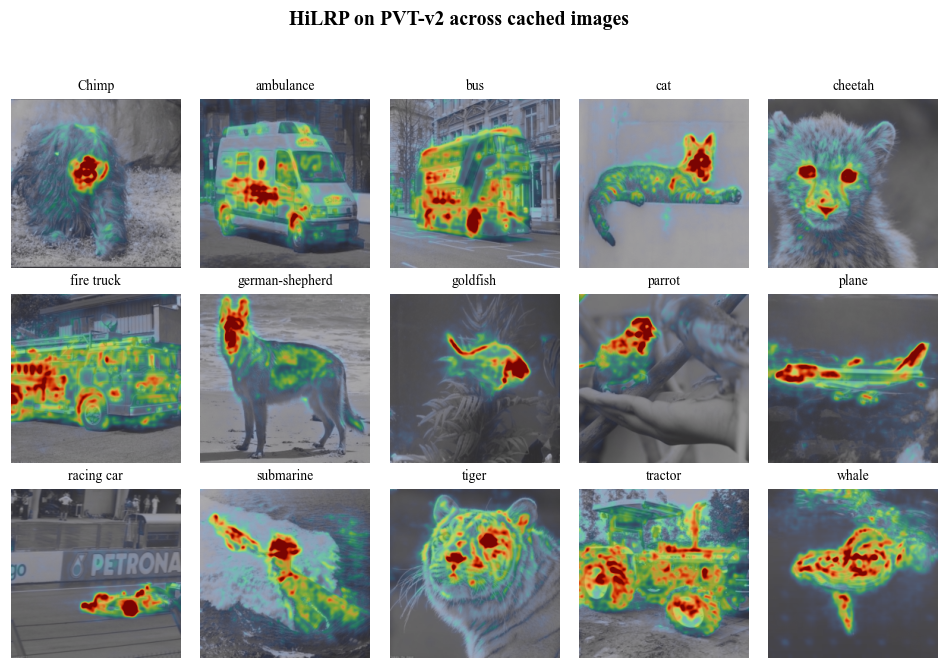

In [18]:
GAL = "qual_gallery"
names = sorted({p.name.split("__")[0] for p in (RES / GAL).glob("*__hilrp.npy")})
ncol = 5; nrow = int(np.ceil(len(names) / ncol))
fig, ax = plt.subplots(nrow, ncol, figsize=(2.2 * ncol, 2.2 * nrow))
ax = np.atleast_2d(ax)
for k, name in enumerate(names):
    a = ax[k // ncol, k % ncol]
    rgb = load_npy(GAL, f"{name}__input"); mp = load_npy(GAL, f"{name}__hilrp")
    if rgb is not None and mp is not None:
        heat_overlay(a, rgb, mp); a.set_title(name, fontsize=9)
    else:
        a.axis("off")
for k in range(len(names), nrow * ncol): ax[k // ncol, k % ncol].axis("off")
plt.suptitle("HiLRP on PVT-v2 across cached images", y=1.002, fontsize=13, fontweight="bold")
plt.subplots_adjust(wspace=0.05, hspace=0.15); plt.show()

---
*Generated from cached results. To refresh the underlying attribution arrays (needs a
GPU and the `lxt` stack), re-run `scripts/bench/cheetah_comparison.py` and the gate
scripts, then re-execute this notebook.*